# 03_preprocessing_v3.ipynb

## v2 대비 변경 사항
- 로드 파일: `hnm_churn_dataset_v3.csv`
- `last_interval` 제거 (interval_t1과 상관관계 1.0 — 완전 중복)
- `interval_t1~t5` NaN 유지 전략 추가
- 저장 파일: `hnm_churn_processed_v3.csv`

## 목차
1. 환경 세팅 및 데이터 로드
2. 중복 피처 제거
3. 결측치 처리
4. 메모리 다운캐스팅
5. 피처 인코딩
6. 전처리 완료 데이터 저장 및 검증
7. 데이터셋 분할


## 1. 환경 세팅 및 데이터 로드

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')

df_analysis = pd.read_csv('../data/hnm_churn_dataset_v3.csv')

print(f'데이터 shape: {df_analysis.shape}')
print(f'결측치 합계: {df_analysis.isnull().sum().sum()}')


데이터 shape: (1143652, 31)
결측치 합계: 4907551


## 2. 중복 피처 제거

EDA 섹션 5에서 확인한 결과:
- `last_interval` ↔ `interval_t1` 상관관계 **1.0** (완전 동일한 정보)
- `last_interval`은 'cut_off 이전 마지막 구매 간격'을 의미하며,
  `interval_t1`이 동일한 값을 담고 있으므로 `last_interval`을 제거합니다.


In [3]:
df_analysis = df_analysis.drop(columns=['last_interval'])

print(f'last_interval 제거 완료')
print(f'shape: {df_analysis.shape}')


last_interval 제거 완료
shape: (1143652, 30)


## 3. 결측치 처리

In [4]:
# 3-1. FN, Active → 0 대치 (마케팅 미동의 의미)
df_analysis['FN']     = df_analysis['FN'].fillna(0)
df_analysis['Active'] = df_analysis['Active'].fillna(0)
print('FN, Active 처리 완료')


FN, Active 처리 완료


In [5]:
# 3-2. age → 중앙값 대치
age_median = df_analysis['age'].median()
df_analysis['age'] = df_analysis['age'].fillna(age_median)
print(f'age 중앙값 대치 완료: {age_median}')


age 중앙값 대치 완료: 32.0


In [6]:
# 3-3. 범주형 변수 → UNKNOWN 대치
cat_missing_cols = ['club_member_status', 'fashion_news_frequency']
for col in cat_missing_cols:
    df_analysis[col] = df_analysis[col].fillna('UNKNOWN')
print('범주형 결측치 처리 완료')


범주형 결측치 처리 완료


In [7]:
# 3-4. NaN 유지 피처 목록 확인
# 아래 피처들은 의도적으로 NaN을 유지합니다.
# - avg/std_purchase_interval: 구매 1회 고객은 간격 계산 불가
# - freq_decay_rate, recent_price_ratio, interval_acceleration:
#   결측 자체가 '최근 구매 없음' = 이탈 신호
# - interval_t1~t5: 구매 횟수 부족 고객은 NaN, 결측 자체가 이탈 신호
#
# 선형/거리 기반 모델 사용 시 아래 주석 해제:
# median_cols = ['avg_purchase_interval', 'std_purchase_interval',
#                'freq_decay_rate', 'recent_price_ratio', 'interval_acceleration',
#                'interval_t1', 'interval_t2', 'interval_t3', 'interval_t4', 'interval_t5']
# for col in median_cols:
#     df_analysis[col] = df_analysis[col].fillna(df_analysis[col].median())

nan_keep_cols = [
    'avg_purchase_interval', 'std_purchase_interval',
    'freq_decay_rate', 'recent_price_ratio', 'interval_acceleration',
    'interval_t1', 'interval_t2', 'interval_t3', 'interval_t4', 'interval_t5'
]
print('NaN 유지 피처 확인:')
for col in nan_keep_cols:
    print(f'  {col:<30}: {df_analysis[col].isnull().sum():,}건 NaN 유지')


NaN 유지 피처 확인:
  avg_purchase_interval         : 111,962건 NaN 유지
  std_purchase_interval         : 218,880건 NaN 유지
  freq_decay_rate               : 465,117건 NaN 유지
  recent_price_ratio            : 684,497건 NaN 유지
  interval_acceleration         : 373,193건 NaN 유지
  interval_t1                   : 111,962건 NaN 유지
  interval_t2                   : 218,880건 NaN 유지
  interval_t3                   : 300,633건 NaN 유지
  interval_t4                   : 371,441건 NaN 유지
  interval_t5                   : 427,734건 NaN 유지


## 4. 메모리 다운캐스팅

In [8]:
# 범주형 → category
cat_encode_cols = ['club_member_status','fashion_news_frequency',
                   'index_group_name','product_group_name']
for col in cat_encode_cols:
    df_analysis[col] = df_analysis[col].astype('category')

# 정수형 다운캐스팅
int_cols = ['churn','recency','frequency','frequency_last_90d',
            'frequency_last_180d','unique_articles',
            'unique_product_groups','unique_articles_last_90d']
for col in int_cols:
    if col == 'churn':
        df_analysis[col] = df_analysis[col].astype('int8')
    else:
        df_analysis[col] = df_analysis[col].astype('int32')

# 실수형 다운캐스팅
float32_cols = [
    'age','price_mean','price_sum','price_max',
    'avg_purchase_interval','std_purchase_interval',
    'freq_decay_rate','recent_price_ratio',
    'diversity_decay_rate','interval_acceleration',
    'interval_t1','interval_t2','interval_t3','interval_t4','interval_t5'
]
for col in float32_cols:
    df_analysis[col] = df_analysis[col].astype('float32')

df_analysis['FN']     = df_analysis['FN'].astype('float16')
df_analysis['Active'] = df_analysis['Active'].astype('float16')

print('다운캐스팅 완료')
df_analysis.info()


다운캐스팅 완료
<class 'pandas.DataFrame'>
RangeIndex: 1143652 entries, 0 to 1143651
Data columns (total 30 columns):
 #   Column                    Non-Null Count    Dtype   
---  ------                    --------------    -----   
 0   customer_id               1143652 non-null  str     
 1   churn                     1143652 non-null  int8    
 2   frequency                 1143652 non-null  int32   
 3   price_mean                1143652 non-null  float32 
 4   price_sum                 1143652 non-null  float32 
 5   price_max                 1143652 non-null  float32 
 6   recency                   1143652 non-null  int32   
 7   frequency_last_90d        1143652 non-null  int32   
 8   frequency_last_180d       1143652 non-null  int32   
 9   avg_purchase_interval     1031690 non-null  float32 
 10  std_purchase_interval     924772 non-null   float32 
 11  unique_articles           1143652 non-null  int32   
 12  unique_product_groups     1143652 non-null  int32   
 13  index_group_na

## 5. 피처 인코딩

In [9]:
# 5-1. 원-핫 인코딩 (drop_first=False: 트리 모델에서 정보 손실 방지)
df_encoded = pd.get_dummies(df_analysis, columns=cat_encode_cols,
                             drop_first=False, dtype='int8')

# 5-2. customer_id 제거
if 'customer_id' in df_encoded.columns:
    df_encoded = df_encoded.drop(columns=['customer_id'])

print(f'인코딩 완료: {df_encoded.shape}')

# 5-3. churn 상관관계 상위 확인 (누수 체크)
corr_with_churn = df_encoded.astype('float32').corr()['churn'].drop('churn')
print('\n--- churn과 상관관계 상위 5개 ---')
print(corr_with_churn.abs().sort_values(ascending=False).head(5).round(4).to_string())


인코딩 완료: (1143652, 55)

--- churn과 상관관계 상위 5개 ---
recency                  0.4812
unique_product_groups    0.4695
unique_articles          0.3768
frequency                0.3587
frequency_last_180d      0.3542


## 6. 전처리 완료 데이터 저장 및 검증

In [10]:
df_encoded.to_csv('../data/hnm_churn_processed_v3.csv', index=False)

df_check = pd.read_csv('../data/hnm_churn_processed_v3.csv')
print(f'저장 완료: {df_check.shape}')
print(f'결측치 합계: {df_check.isnull().sum().sum()}')
# interval_t1~t5, avg/std_purchase_interval 등 NaN 유지 → 0이 아니어도 정상
print(f'컬럼 목록:\n{list(df_check.columns)}')


저장 완료: (1143652, 55)
결측치 합계: 3284299
컬럼 목록:
['churn', 'frequency', 'price_mean', 'price_sum', 'price_max', 'recency', 'frequency_last_90d', 'frequency_last_180d', 'avg_purchase_interval', 'std_purchase_interval', 'unique_articles', 'unique_product_groups', 'freq_decay_rate', 'recent_price_ratio', 'unique_articles_last_90d', 'diversity_decay_rate', 'interval_acceleration', 'interval_t1', 'interval_t2', 'interval_t3', 'interval_t4', 'interval_t5', 'FN', 'Active', 'age', 'club_member_status_ACTIVE', 'club_member_status_LEFT CLUB', 'club_member_status_PRE-CREATE', 'club_member_status_UNKNOWN', 'fashion_news_frequency_Monthly', 'fashion_news_frequency_NONE', 'fashion_news_frequency_Regularly', 'fashion_news_frequency_UNKNOWN', 'index_group_name_Baby/Children', 'index_group_name_Divided', 'index_group_name_Ladieswear', 'index_group_name_Menswear', 'index_group_name_Sport', 'product_group_name_Accessories', 'product_group_name_Bags', 'product_group_name_Cosmetic', 'product_group_name_Furnitur

## 7. 데이터셋 분할

In [11]:
X = df_encoded.drop(columns=['churn'])
y = df_encoded['churn']

# random_state=42 고정 → 04 모델 노트북과 동일한 분할 보장
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'X_train: {X_train.shape}, X_val: {X_val.shape}')
print(f'y_train 이탈률: {y_train.mean():.4f}')
print(f'y_val   이탈률: {y_val.mean():.4f}')


X_train: (914921, 54), X_val: (228731, 54)
y_train 이탈률: 0.5002
y_val   이탈률: 0.5002


In [12]:
# 분할 데이터 저장
X_train.to_csv('../data/X_train_v3.csv', index=False)
X_val.to_csv('../data/X_val_v3.csv',     index=False)
y_train.to_csv('../data/y_train_v3.csv', index=False)
y_val.to_csv('../data/y_val_v3.csv',     index=False)

print('분할 데이터 저장 완료')
print(f'  X_train_v3.csv : {X_train.shape}')
print(f'  X_val_v3.csv   : {X_val.shape}')


분할 데이터 저장 완료
  X_train_v3.csv : (914921, 54)
  X_val_v3.csv   : (228731, 54)


In [14]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 캐시 삭제 후 폰트 재등록
fm._load_fontmanager(try_read_cache=False)

# 맑은 고딕 강제 지정
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 적용 확인
print(plt.rcParams['font.family'])

['Malgun Gothic']


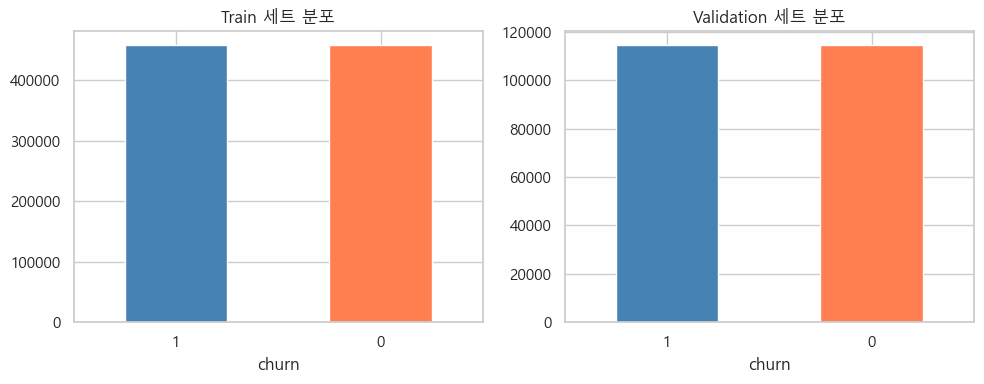

In [15]:
# 분할 후 클래스 비율 시각화
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
y_train.value_counts().plot(kind='bar', ax=axes[0], title='Train 세트 분포',
                             color=['steelblue','coral'], rot=0)
y_val.value_counts().plot(kind='bar',   ax=axes[1], title='Validation 세트 분포',
                           color=['steelblue','coral'], rot=0)
plt.tight_layout(); plt.show()
